# E233 · Learn, replay, or freeze?

**Complete** · E233 finished · Phase C gate stayed closed  
Updated 2026-11-23T12:35:50+01:00 Stockholm

Eight fresh capture-disjoint BDD walks each use a 384-arrival initial A clip, B clip and distinct returning A clip. Every policy starts from the same A-trained state. Each B and returning-A clip has two recorded segments, with up to 96 optimizer updates per segment. The policies carry forward both weights and optimizer state. Freeze observes the stream and saves its scheduled training updates. Historical memory contains earlier observed frames.

The primary score equally weights the independent A and B panels, each containing scene, weather, traffic-light and pedestrian balanced accuracy. Separate raw holdouts anchor the A/B keyframe panels. Lighting is outside the primary aggregate. Semantic labels only enter evaluation. Bootstrap intervals resample whole walks and condition on the shared keyframe corpus. Training time includes update work and replay-bank setup. The common A warmup and evaluation are tracked separately.

| Walk | A to B distance | Minimum labeled class count, A | Minimum labeled class count, B |
| --- | --- | --- | --- |
| 1 | 0.355 | 25 | 38 |
| 2 | 0.338 | 26 | 36 |
| 3 | 0.584 | 25 | 37 |
| 4 | 0.256 | 25 | 33 |
| 5 | 0.266 | 27 | 41 |
| 6 | 0.983 | 25 | 37 |
| 7 | 0.166 | 26 | 40 |
| 8 | 0.296 | 25 | 32 |

## Phase A · Closed-loop compute–quality frontier

| Policy | B / return behavior | Endpoint score (%) | Time-averaged score (%) | Endpoint vs Incoming (pp) | Updates | Replay exposures | Training seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Incoming always | Incoming / Incoming | +51.679 [+51.479, +51.866] | +51.716 [+51.514, +51.915] | +0.000 [+0.000, +0.000] | 384 | 0 | 3.95 |
| Fixed 25% replay | 25% replay / 25% replay | +52.257 [+51.820, +52.682] | +51.943 [+51.668, +52.215] | +0.578 [+0.266, +0.887] | 384 | 192 | 3.85 |
| Replay on return | Incoming / 50% replay | +52.193 [+51.948, +52.467] | +51.922 [+51.690, +52.137] | +0.514 [+0.342, +0.699] | 384 | 192 | 3.81 |
| Freeze on return | Incoming / Freeze | +51.816 [+51.537, +52.085] | +51.757 [+51.502, +52.008] | +0.137 [-0.167, +0.437] | 192 | 0 | 1.90 |
| Freeze throughout | Freeze / Freeze | +51.351 [+51.046, +51.643] | +51.351 [+51.046, +51.643] | -0.328 [-0.477, -0.161] | 0 | 0 | 0.00 |

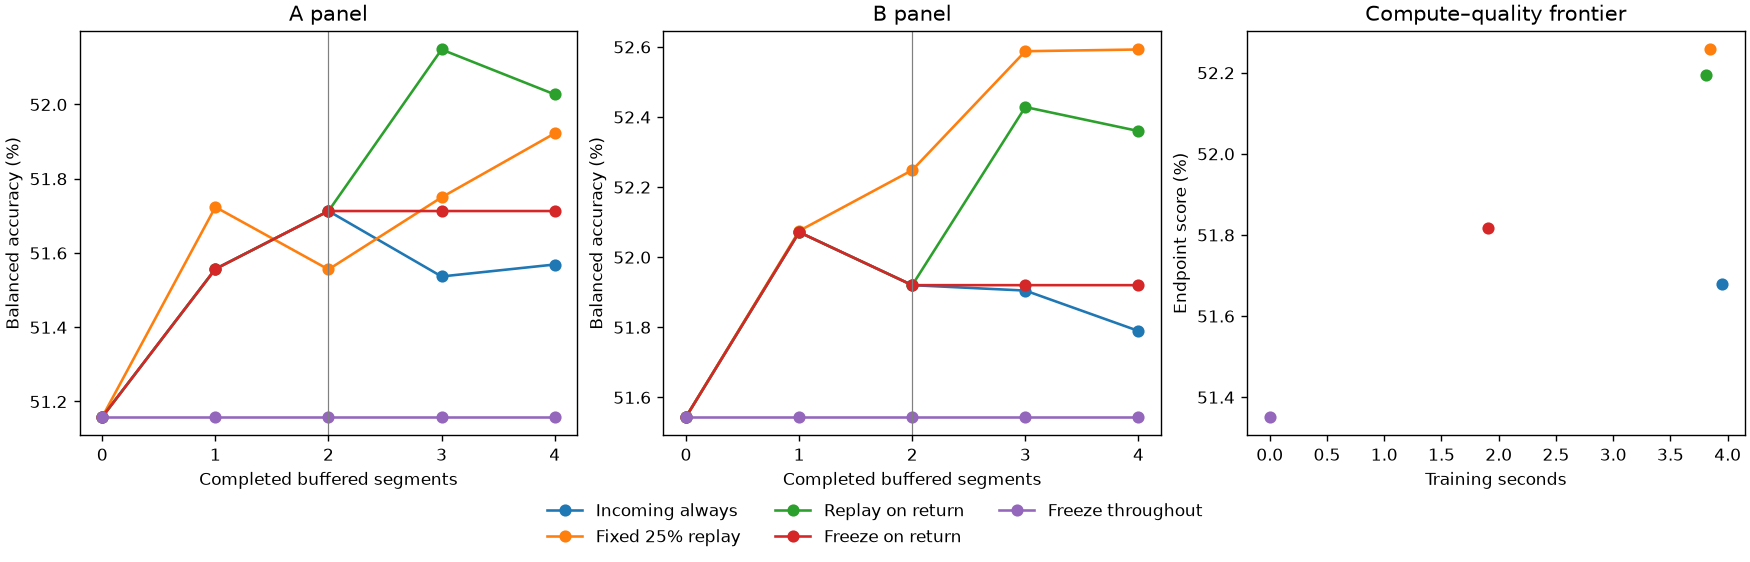

## Phase B · Independent-draw action opportunity

Four common checkpoints per walk are reached by the incoming-only reference. Branches evaluate incoming, 50% replay or freeze for one full segment. Three development mask draws select an action. Two fresh paired draws evaluate it. The comparison uses the strongest single action across the fresh draws, recomputed in each walk bootstrap sample.

**Oracle gain over Replay 50%** +0.038 [-0.003, +0.082] pp. 21 states had a clear winner across both test draws. 3 walks had at least two different clear winners. Near ties within 0.10 pp are excluded from this count.

| Segment | Incoming | Replay 50% | Freeze |
| --- | --- | --- | --- |
| 1 | 1 | 6 | 1 |
| 2 | 2 | 4 | 2 |
| 3 | 0 | 7 | 1 |
| 4 | 0 | 8 | 0 |

**Phase C gate stayed closed.** It requires +0.25 pp and a positive lower walk interval, distinct repeated choices on at least 4 walks, and at least 20 labeled examples in each primary class and panel.